# F26-07 — Phase 3: Model Building and Evaluation
## AI-Powered E-Commerce Analytics and Conversational Agent System

**Course:** Artificial Intelligence  
**Team:** Eman Fatima (24L-3008), Abdullah Tahir (24L-3061), Shahzaib Zia (24L-3057), Rabia (24L-3093)

This notebook implements a hybrid conversational agent using the Phase 2 synthetic dataset. It trains an intent/action classifier, builds a TF-IDF policy retrieval pipeline, exposes structured catalog/order tools, applies guardrails, and evaluates predictions on the reserved test split.

**Place these files in the same folder as this notebook:** `catalog.csv`, `orders.csv`, `conversations.json`, `policy.md`, `policy_rules.json`.


## 1. Libraries and data loading
We use pandas for structured data, scikit-learn for the classifier and retrieval embeddings, and Python regular expressions for text normalization. No external API key is required for this baseline implementation.

In [1]:
import json, re
from pathlib import Path
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from IPython.display import display

DATA_DIR = Path(".")
catalog = pd.read_csv(DATA_DIR / "catalog.csv", dtype={"size": str})
orders = pd.read_csv(DATA_DIR / "orders.csv", dtype=str)
conversations = json.loads((DATA_DIR / "conversations.json").read_text(encoding="utf-8"))["conversations"]
policy_text = (DATA_DIR / "policy.md").read_text(encoding="utf-8")
policy_rules = json.loads((DATA_DIR / "policy_rules.json").read_text(encoding="utf-8"))

print("Catalog:", catalog.shape, "| Orders:", orders.shape, "| Conversations:", len(conversations))
print("Development:", sum(c["split"]=="dev" for c in conversations),
      "| Test:", sum(c["split"]=="test" for c in conversations))
display(catalog.head())


Catalog: (572, 11) | Orders: (51, 12) | Conversations: 172
Development: 120 | Test: 52


,sku,product_id,name,category,color,size,original_price,price,stock,is_sale,description
0,SKU0001,P001,Linen Kurta,Men Kurta,Black,S,2499,2499,5,False,"Breathable pure linen kurta, straight cut, ide..."
1,SKU0002,P001,Linen Kurta,Men Kurta,Black,M,2499,2499,12,False,"Breathable pure linen kurta, straight cut, ide..."
2,SKU0003,P001,Linen Kurta,Men Kurta,Black,L,2499,2499,1,False,"Breathable pure linen kurta, straight cut, ide..."
3,SKU0004,P001,Linen Kurta,Men Kurta,Black,XL,2499,2499,22,False,"Breathable pure linen kurta, straight cut, ide..."
4,SKU0005,P001,Linen Kurta,Men Kurta,White,S,2499,2499,0,False,"Breathable pure linen kurta, straight cut, ide..."


## 2. Text preparation and train/test split
Each conversation's customer turns are concatenated to preserve multi-turn context. The provided Phase 2 split is retained: 120 development conversations and 52 held-out test conversations. The test set is not used for model fitting.

In [2]:
def normalize(text):
    text = str(text).lower().strip()
    text = re.sub(r"\b(03\d{2})[-\s](\d{7})\b", r"\1\2", text)
    text = re.sub(r"[^\w\s-]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def conversation_text(conv):
    return " [TURN] ".join(t["text"] for t in conv["turns"] if t["speaker"] == "customer")

dev = [c for c in conversations if c["split"] == "dev"]
test = [c for c in conversations if c["split"] == "test"]
X_train = [normalize(conversation_text(c)) for c in dev]
y_train = [c["expected"]["expected_action"] for c in dev]
X_test = [normalize(conversation_text(c)) for c in test]
y_test = [c["expected"]["expected_action"] for c in test]
print(f"Training examples: {len(X_train)} | Test examples: {len(X_test)}")


Training examples: 120 | Test examples: 52


## 3. Train the intent/action classifier
A TF-IDF + Logistic Regression pipeline is used as a lightweight baseline. TF-IDF converts messages into weighted word features; bigrams capture short phrases, while Logistic Regression predicts one of the expected backend actions. `class_weight='balanced'` helps reduce bias toward frequent labels. The model is fitted only on the development split.

In [3]:
intent_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), analyzer="word",
                              sublinear_tf=True, min_df=1)),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced",
                                       random_state=42))
])
intent_model.fit(X_train, y_train)
predictions = intent_model.predict(X_test)
intent_accuracy = accuracy_score(y_test, predictions)
print("Held-out action accuracy:", round(intent_accuracy, 4))
print(classification_report(y_test, predictions, zero_division=0))


Held-out action accuracy: 0.7692
                      precision    recall  f1-score   support

       answer_policy       1.00      1.00      1.00         6
         check_stock       0.90      0.90      0.90        10
     create_exchange       0.20      1.00      0.33         1
        create_order       0.64      1.00      0.78         7
deny_status_mismatch       0.50      1.00      0.67         1
            escalate       0.91      0.56      0.69        18
    get_order_status       1.00      0.75      0.86         4
           recommend       1.00      0.67      0.80         3
request_confirmation       1.00      0.50      0.67         2
request_missing_info       0.00      0.00      0.00         0

            accuracy                           0.77        52
           macro avg       0.71      0.74      0.67        52
        weighted avg       0.88      0.77      0.79        52



## 4. RAG retrieval pipeline for store policy
Policy text is split by Markdown section headings. TF-IDF vectors act as sparse text embeddings; a query is vectorized in the same space and ranked using cosine-equivalent dot-product similarity (the vectorizer's default L2 normalization). This provides a working retrieval baseline without a paid embedding API. Catalog prices and stock are retrieved from structured data tools rather than generated from policy text.

In [4]:
def split_policy(text):
    sections = re.split(r"(?=^## )", text, flags=re.MULTILINE)
    return [s.strip() for s in sections if s.strip()]

policy_chunks = split_policy(policy_text)
rag_vectorizer = TfidfVectorizer(ngram_range=(1, 2))
policy_embeddings = rag_vectorizer.fit_transform(policy_chunks)

def retrieve_policy(query, top_k=3):
    q = rag_vectorizer.transform([normalize(query)])
    scores = (policy_embeddings @ q.T).toarray().ravel()
    ranked = scores.argsort()[::-1][:top_k]
    return [{"section": policy_chunks[i].splitlines()[0].replace("#", "").strip(),
             "score": round(float(scores[i]), 4), "text": policy_chunks[i]}
            for i in ranked]

for item in retrieve_policy("Lahore delivery charges and cash on delivery", 2):
    print(item["section"], "score=", item["score"])


3. Payment (COD) score= 0.2555
2. Delivery Areas and Charges score= 0.2324


## 5. Structured backend tools
These functions use the CSV/JSON assets as the source of truth. They are deterministic Python tools, not LLM-generated database answers. Order status requires both order ID and matching phone number.

In [5]:
def check_stock(product, color, size):
    rows = catalog[
        catalog["name"].str.lower().eq(str(product).lower()) &
        catalog["color"].str.lower().eq(str(color).lower()) &
        catalog["size"].str.lower().eq(str(size).lower())
    ]
    if rows.empty:
        return {"found": False, "message": "Variant not found; ask a clarification."}
    r = rows.iloc[0]
    return {"found": True, "sku": r.sku, "price": int(r.price),
            "stock": int(r.stock), "is_sale": bool(r.is_sale)}

def check_delivery_policy(city):
    tier_a = [x.lower() for x in policy_rules["delivery"]["tier_a_cities"]]
    charge = policy_rules["delivery"]["tier_a_charge"] if city.lower() in tier_a else policy_rules["delivery"]["default_charge"]
    eta = policy_rules["delivery"]["eta_days_tier_a"] if city.lower() in tier_a else policy_rules["delivery"]["eta_days_other"]
    return {"city": city, "delivery_charge": int(charge), "eta_days": eta,
            "cod_available": bool(policy_rules["payment"]["cod_available"])}

def get_order_status(order_id, phone):
    row = orders[orders["order_id"].astype(str).eq(str(order_id))]
    if row.empty:
        return {"found": False, "action": "escalate"}
    r = row.iloc[0]
    if re.sub(r"\D", "", str(r.phone)) != re.sub(r"\D", "", str(phone)):
        return {"found": True, "action": "deny_status_mismatch", "share_details": False}
    return {"found": True, "action": "get_order_status", "status": r.status,
            "courier": r.courier, "tracking_no": r.tracking_no}

def recommend_products(category=None, budget=None, limit=5):
    df = catalog[catalog.stock.astype(int) > 0].copy()
    if category:
        df = df[df.category.str.lower().eq(category.lower())]
    if budget is not None:
        df = df[df.price.astype(float) <= float(budget)]
    return df.sort_values(["price", "stock"], ascending=[True, False]).head(limit)[
        ["name", "color", "size", "price", "stock", "category"]]

display(pd.DataFrame([check_stock("Linen Kurta", "Black", "M")]))
print(check_delivery_policy("Lahore"))
print("Wrong-phone privacy test:", get_order_status("10231", "03459998888"))


,found,sku,price,stock,is_sale
0,True,SKU0002,2499,12,False


{'city': 'Lahore', 'delivery_charge': 250, 'eta_days': [2, 4], 'cod_available': True}
Wrong-phone privacy test: {'found': True, 'action': 'deny_status_mismatch', 'share_details': False}


## 6. System prompt and grounded prompt assembly
The system prompt defines language, grounding, privacy, confirmation and escalation behaviour. The helper combines the prompt with retrieved policy sections and optional verified tool output. This configures the prompt/RAG interface; no external generative-model API is called in this baseline.

In [6]:

# 6. System prompt and grounded prompt assembly
SYSTEM_PROMPT = """You are the customer-support assistant for Saira Fashion House.
Reply briefly and politely in the customer's language mix (Roman Urdu/English).
Use ONLY the supplied catalog/tool results and retrieved store-policy context.
Never invent product names, prices, stock, delivery charges, tracking details, or policies.
Never reveal order information unless both order ID and matching phone number are verified.
Never approve or promise refunds. Escalate refunds, returns, damaged/wrong items,
complaints, legal threats, discounts, cancellations, bulk orders above limits,
unclear requests after two clarifications, and low-confidence cases to a human.
Before placing an order, collect all required fields, show a complete order summary,
and wait for explicit customer confirmation. Do not claim an order was created
unless the order tool confirms success. If evidence is missing, ask a question or escalate."""

def build_grounded_prompt(user_message, retrieved=None, tool_result=None):
    retrieved = retrieved or retrieve_policy(user_message, top_k=3)
    context = "\n\n".join(
        f"[{item['section']}]\\n{item['text']}" for item in retrieved
    )
    return {
        "system": SYSTEM_PROMPT,
        "user": user_message,
        "grounding_context": context,
        "verified_tool_result": tool_result
    }

sample_prompt = build_grounded_prompt(
    "Lahore mein COD hai? delivery charges kitne honge?"
)
print("System prompt configured:", bool(sample_prompt["system"]))
print("Retrieved grounding context characters:", len(sample_prompt["grounding_context"]))


System prompt configured: True
Retrieved grounding context characters: 2473


## 7. Guardrails and end-to-end classification
Policy keywords that indicate refunds, returns, damage, complaints, legal threats, discounts, cancellations, or a human request force escalation. A low-confidence threshold also routes a prediction to a human. This is a conservative baseline; the threshold must be tuned using development data and expanded tests before deployment.

In [7]:
ESCALATION_TERMS = ["refund", "return", "damaged", "phat", "kharab",
                    "wrong item", "complaint", "cancel", "discount",
                    "court", "wakeel", "insan se", "owner se", "human"]

def guardrail(text, predicted_action, confidence):
    low = normalize(text)
    if any(term in low for term in ESCALATION_TERMS):
        return {"allow_action": False, "action": "escalate",
                "reason": "policy_keyword_or_human_request"}
    if confidence < 0.45:
        return {"allow_action": False, "action": "escalate",
                "reason": "low_classifier_confidence"}
    return {"allow_action": True, "action": predicted_action, "reason": None}

def classify_message(text):
    probs = intent_model.predict_proba([normalize(text)])[0]
    idx = probs.argmax()
    label, confidence = intent_model.classes_[idx], float(probs[idx])
    return {"predicted_action": label, "confidence": round(confidence, 4),
            **guardrail(text, label, confidence)}

def agent_demo(text):
    result = classify_message(text)
    result["retrieved_policy"] = retrieve_policy(text, top_k=2)
    return result

agent_demo("Lahore mein COD hai? delivery charges kitne honge?")


{'predicted_action': np.str_('answer_policy'),
 'confidence': 0.3338,
 'allow_action': False,
 'action': 'escalate',
 'reason': 'low_classifier_confidence',
 'retrieved_policy': [{'section': '10. Frequently Asked Questions (Roman Urdu / English)',
   'score': 0.2448,
   'text': '## 10. Frequently Asked Questions (Roman Urdu / English)\n\n**Delivery kitne din mein hogi? (How many days does delivery take?)**\nLahore, Gujranwala, Sialkot, Sheikhupura, Faisalabad, Islamabad and Rawalpindi: 2 to 4 working days. Other cities: 4 to 6 working days.\n\n**COD available hai? (Is COD available?)**\nYes, COD is available in all delivery areas. For orders above Rs. 25,000 a staff member will confirm the payment first.\n\n**Delivery charges kitne hain? (What are the delivery charges?)**\nRs. 250 for major cities, Rs. 350 for other areas. Delivery is free on orders of Rs. 10,000 or more.\n\n**Exchange ho sakta hai? (Can I exchange?)**\nYes, within 7 days of delivery for non-sale items that are unused 

## 8. Evaluation and limitations
The main quantitative baseline is held-out expected-action accuracy. Because the test set is small and imbalanced, per-class precision/recall should be interpreted cautiously. Tool correctness is demonstrated separately with deterministic examples. The current prototype does not yet implement a full persistent multi-user chat state, transactional stock reservation/locking, a production LLM response generator, or a visual dashboard; these remain future implementation tasks rather than claimed features.

Test action accuracy: 0.7692
                      precision    recall  f1-score   support

       answer_policy       1.00      1.00      1.00         6
         check_stock       0.90      0.90      0.90        10
     create_exchange       0.20      1.00      0.33         1
        create_order       0.64      1.00      0.78         7
deny_status_mismatch       0.50      1.00      0.67         1
            escalate       0.91      0.56      0.69        18
    get_order_status       1.00      0.75      0.86         4
           recommend       1.00      0.67      0.80         3
request_confirmation       1.00      0.50      0.67         2
request_missing_info       0.00      0.00      0.00         0

            accuracy                           0.77        52
           macro avg       0.71      0.74      0.67        52
        weighted avg       0.88      0.77      0.79        52



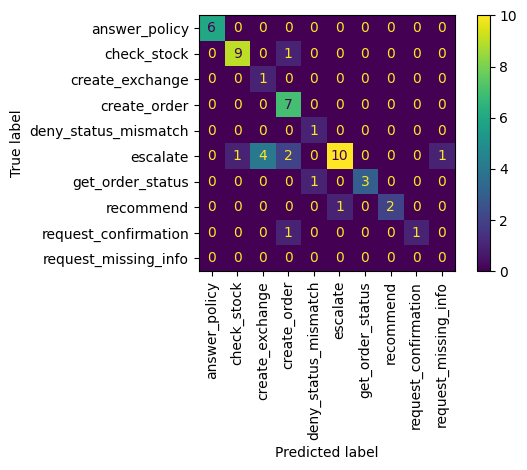

Stock lookup => {'found': True, 'sku': 'SKU0002', 'price': 2499, 'stock': 12, 'is_sale': False}
Delivery policy => {'city': 'Lahore', 'delivery_charge': 250, 'eta_days': [2, 4], 'cod_available': True}
Order privacy guard => {'found': True, 'action': 'deny_status_mismatch', 'share_details': False}


In [8]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("Test action accuracy:", round(accuracy_score(y_test, predictions), 4))
print(classification_report(y_test, predictions, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, xticks_rotation=90)
plt.tight_layout()
plt.show()

# Example output checks
examples = [
    ("Stock lookup", check_stock("Linen Kurta", "Black", "M")),
    ("Delivery policy", check_delivery_policy("Lahore")),
    ("Order privacy guard", get_order_status("10231", "03459998888")),
]
for title, output in examples:
    print(title, "=>", output)
